# LadderFuelsR — vertical fuel continuity & crown base height from LiDAR (minimal reproduction)

**Paper:** Viedma, O.; Silva, C.; Moreno, J.M.; Hudak, A.T. (2024) *LadderFuelsR: A new automated tool for vertical fuel continuity analysis and crown base height detection using light detection and ranging.* Methods in Ecology and Evolution 15(11):1958–1967. [DOI 10.1111/2041-210X.14427](https://doi.org/10.1111/2041-210X.14427) (CC BY 4.0)

**Code:** `LadderFuelsR` **0.0.7** (CRAN, GPL-3) — author repository [`olgaviedma/LadderFuelsR`](https://github.com/olgaviedma/LadderFuelsR) @ commit `6eb099c164b227dac68f5d06d781bd5ef13794fd`.

**Executed scope (partial demonstration):** the paper's core workflow — gaps & fuel-base-height (FBH) detection, LAD percentiles, inter-layer distances, layer depths, effective layers, LAD% per layer, and the three CBH criteria plus the segmented-regression breakpoint CBH (README steps 8–22) — run on the **authors' own bundled sample** `inst/extdata/LAD_profiles.txt` (the exact input their package tests use). All LadderFuelsR computations are the authors' R code, unmodified.

**Not executed (out of scope):** README steps 1–7 (CHM/tree/crown segmentation and leafR voxel LAD profiling). `leafR` was removed from CRAN (2026-03-21) and requires `lidR`; the authors ship the resulting LAD-profile table themselves, which is the scientific input to the paper's core method.

**Runtime: CPU only** (tabular R computation; no GPU path exists in the package).

*This notebook launches the authors' R package via `Rscript`; Python is only the launcher because the Colab CLI cannot execute a native R-kernel notebook. The orchestration (not the science) is AI-assisted; author R code and author data are used unmodified.*

**日本語:** このノートブックは LiDAR による垂直燃料連続性・樹冠基底高（CBH）解析ツール **LadderFuelsR 0.0.7** の最小再現です。著者捆包のサンプル LAD プロファイル `LAD_profiles.txt` を用い、ギャップ/燃料層基底高（FBH）検出・距離・深度・有効層・LAD%・3 種の CBH 基準・折れ点回帰 CBH（README ステップ 8–22）を実行します。R は `Rscript` 経由で実行します（Python は起動器のみ）。**CPU のみ**で動作します。ステップ 1–7（CHM・樹冠分割・leafR による LAD 計算）は対象外です（leafR は CRAN から削除済みのため）。

## 1. Runtime selection & how to run

Select **Runtime → Change runtime type → CPU** (the default). There is no GPU code path in LadderFuelsR — the method is percentile/tabular R computation on kilobyte-scale tables, so a GPU would not change anything.

Press **Runtime → Run all**. Expected wall time: ≈5–15 min, dominated by R package installation (~2–10 min with prebuilt binaries, up to ~30 min if source compilation fallback is used). Downloads: ≈1.4 KB of sample data + R packages.

**日本語:** 「ランタイム」→「ランタイムのタイプを変更」→ **CPU** を選択してから「すべてのセルを実行」してください。GPU は不要です（表計算のみ）。所要時間は 5–15 分程度で、大半は R パッケージのインストールです。

In [ ]:
import subprocess

RSCRIPT = "/usr/bin/Rscript"
result = subprocess.run([RSCRIPT, "--version"], capture_output=True, text=True, timeout=120)
print(result.stdout.strip() or result.stderr.strip())


Rscript (R) version 4.6.1 (2026-06-24)


## 2. Install the R packages

We install **LadderFuelsR 0.0.7** from a pinned Posit Public Package Manager snapshot of CRAN (`2024-11-05`, Ubuntu jammy binaries — fast), falling back to the official CRAN cloud mirror if the snapshot is unreachable. LadderFuelsR is pure R (`NeedsCompilation: no`) and imports dplyr, gdata, ggplot2, magrittr, segmented, stringr, tidyr, tibble, tidyselect.

**日本語:** LadderFuelsR 0.0.7 を固定日付スナップショット（2024-11-05）からバイナリで導入します（失敗時は CRAN クラウドからソースビルドにフォールバック）。

In [ ]:
install_code = r"""
options(warn = 1)
repos <- c("https://packagemanager.posit.co/cran/__linux__/jammy/2024-11-05",
           "https://cloud.r-project.org")
install.packages("LadderFuelsR", repos = repos, dependencies = TRUE, Ncpus = 2)
cat("LadderFuelsR installed:", as.character(packageVersion("LadderFuelsR")), "\n")
"""
result = subprocess.run([RSCRIPT, "-e", install_code], check=True, capture_output=True, text=True, timeout=3000)
print(result.stdout)


begin installing package ‘gtools’
begin installing package ‘segmented’
* installing *source* package ‘gtools’ ...
** this is package ‘gtools’ version ‘3.9.5’
** package ‘gtools’ successfully unpacked and MD5 sums checked
** using staged installation
** libs
using C compiler: ‘x86_64-linux-gnu-gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0’
make[1]: Entering directory '/tmp/Rtmpg89TX5/R.INSTALL7014ccab8cf/gtools/src'
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=. -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=/build/r-base-2C2QGL/r-base-4.6.1=/usr/src/r-base-4.6.1-9.2404.0 -Wdate-time -D_FORTIFY_SOURCE=3  -c init.c -o init.o
x86_64-linux-gnu-gcc -std=gnu2x -I"/usr/share/R/include" -DNDEBUG       -fpic  -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-m

We verify the package actually loads and record the versions used by this session.

**日本語:** パッケージが実際に読み込めるか確認し、本セッションのバージョンを記録します。

In [ ]:
version_code = r"""
suppressPackageStartupMessages(library(LadderFuelsR))
cat(R.version.string, "\n")
for (p in c("LadderFuelsR", "dplyr", "ggplot2", "segmented", "tidyr")) {
  cat(p, as.character(packageVersion(p)), "\n")
}
"""
result = subprocess.run([RSCRIPT, "-e", version_code], check=True, capture_output=True, text=True, timeout=300)
print(result.stdout)


R version 4.6.1 (2026-06-24) 
LadderFuelsR 0.0.7 
dplyr 1.2.1 
ggplot2 4.0.3 
segmented 2.2.2 
tidyr 1.3.2 



## 3. Minimal input: the authors' bundled LAD-profile sample

**Sample:** `inst/extdata/LAD_profiles.txt` from `olgaviedma/LadderFuelsR` @ `6eb099c164b227dac68f5d06d781bd5ef13794fd` (≈1.4 KB).
It is a `treeID`/`height`/`lad` table of Leaf-Area-Density profiles per 1 m height bin — the same input format produced by `leafR::lad.profile` in README step 7 and consumed by the package's own tests (`tests/testthat/test-calculate_gaps_perc.R`). Units: `height` in metres, `lad` in leaf area per unit volume (profile units as shipped by the authors).

**日本語:** 著者らがパッケージに同梱するサンプル LAD プロファイル表（treeID・height[m]・lad）をピン留めしたコミットから取得します。これは著者らのテストが使用する入力そのものです。

In [ ]:
import hashlib, pathlib, urllib.request

COMMIT = "6eb099c164b227dac68f5d06d781bd5ef13794fd"
RAW_URL = f"https://raw.githubusercontent.com/olgaviedma/LadderFuelsR/{COMMIT}/inst/extdata/LAD_profiles.txt"
dest = pathlib.Path("/content/data/LAD_profiles.txt")
dest.parent.mkdir(parents=True, exist_ok=True)
request = urllib.request.Request(RAW_URL, headers={"User-Agent": "colab-repro-notebook"})
raw = urllib.request.urlopen(request, timeout=120).read()
header_line = raw.split(b"\n", 1)[0]
required = (b"height", b"lad", b"treeID")
assert all(col in header_line for col in required), f"unexpected file header: {header_line[:80]!r}"
dest.write_bytes(raw)
print("downloaded:", RAW_URL)
print("bytes:", len(raw))
print("sha256:", hashlib.sha256(raw).hexdigest())
print("header:", header_line.decode())


downloaded: https://raw.githubusercontent.com/olgaviedma/LadderFuelsR/6eb099c164b227dac68f5d06d781bd5ef13794fd/inst/extdata/LAD_profiles.txt
bytes: 1364
sha256: 64d27efbaf64c660e51eb8b176e515deb41ee42b32a441c8c75f8678d61f07dc
header: "height"	"lad"	"treeID"


A first, non-scientific inspection of the sample: columns, tree IDs, and height bins. The workflow below loops over **all** trees present (the README loops are generic), so the demo adapts to whatever trees the authors shipped. The README's §16/§21 snippets hardcode `treeID == "1_CROWN"` inside a loop — a README bug (the loop variable is unused) that we replace with the intended per-tree loop.

**日本語:** サンプルの列・樹木 ID・高さビンを確認します。以下のワークフローは README の意図通り「全樹木」をループ処理します（README §16/§21 の `1_CROWN` ハードコードは README 側のバグのため、汎用ループに置き換え）。

In [ ]:
import pandas as pd

profiles = pd.read_csv("/content/data/LAD_profiles.txt", sep="\t")
print(profiles.dtypes)
print("rows:", len(profiles))
print("trees:", sorted(profiles.treeID.unique()))
print("height range [m]:", profiles.height.min(), "-", profiles.height.max())
print(profiles.head(8).to_string(index=False))


height    float64
lad       float64
treeID     object
dtype: object
rows: 41
trees: ['100_Eglin_zone1_CROWN', '10_Eglin_zone1_CROWN', '1_Eglin_zone1_CROWN']
height range [m]: 1.5 - 15.5
 height    lad              treeID
    1.5 0.0172 1_Eglin_zone1_CROWN
    2.5 0.0000 1_Eglin_zone1_CROWN
    3.5 0.0000 1_Eglin_zone1_CROWN
    4.5 0.0000 1_Eglin_zone1_CROWN
    5.5 0.0000 1_Eglin_zone1_CROWN
    6.5 0.1014 1_Eglin_zone1_CROWN
    7.5 0.2985 1_Eglin_zone1_CROWN
    8.5 0.0161 1_Eglin_zone1_CROWN


### Input preview — LAD profiles per tree

We plot the actual sample input before any analysis: Leaf Area Density (`lad`) versus height bin for every tree. This is the raw material the gap/FBH detector works on.

**日本語:** 解析前に実際の入力（樹木ごとの LAD プロファイル）を可視化します。

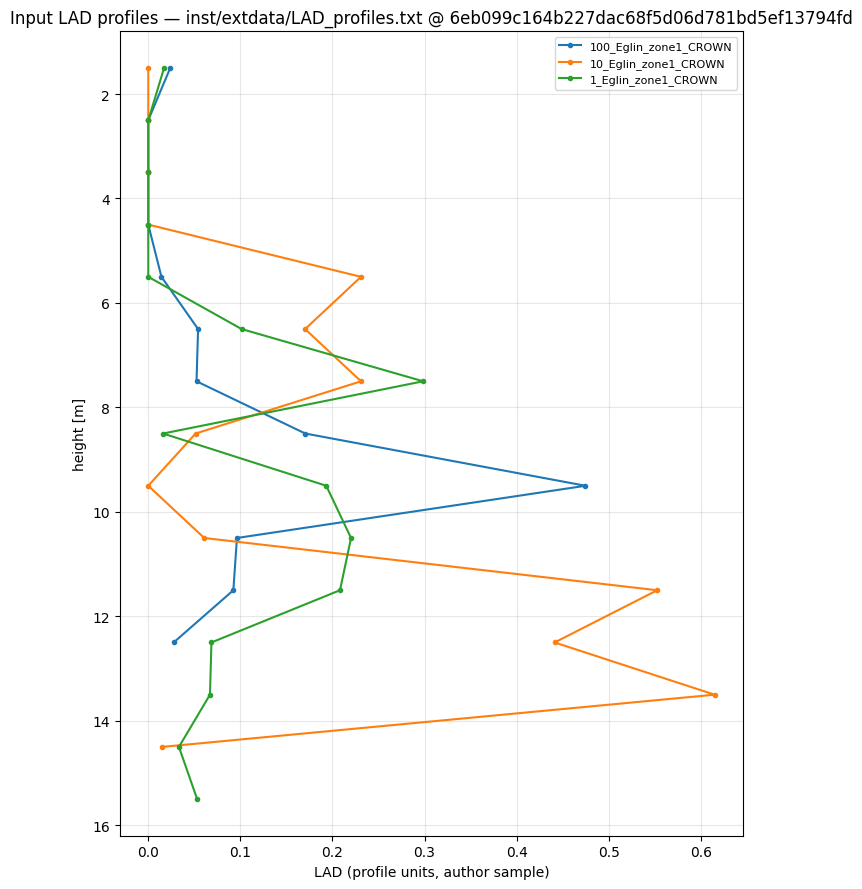

In [ ]:
import matplotlib.pyplot as plt
import pathlib

pathlib.Path("/content/outputs").mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 9))
for tree_id, grp in profiles.groupby("treeID"):
    ax.plot(grp.lad, grp.height, marker="o", ms=3, label=str(tree_id))
ax.invert_yaxis()
ax.set_xlabel("LAD (profile units, author sample)")
ax.set_ylabel("height [m]")
ax.legend(fontsize=8)
ax.set_title("Input LAD profiles — inst/extdata/LAD_profiles.txt @ " + COMMIT)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("/content/outputs/00_lad_profiles_input.png", dpi=110)
plt.show()


## 4. Step 8 — Depurate the LAD profiles (README §8)

Round `lad` to 4 digits, keep trees with more than 5 profile rows, and replace `NA` with 0.01 — exactly the authors' `profile_list2` construction. Output: the cleaned profile table handed to the gap detector.

**日本語:** README §8 に従い、`lad` を小数 4 桁に丸め、5 行超のプロファイルを持つ樹木だけを残し、`NA` を 0.01 に置換します。

In [ ]:
depurate_r = r"""
suppressPackageStartupMessages({library(LadderFuelsR); library(dplyr); library(tidyr)})
dat <- read.table("/content/data/LAD_profiles.txt", header = TRUE)
stopifnot(all(c("treeID", "height", "lad") %in% names(dat)))
dat$treeID <- factor(dat$treeID)
dat$lad <- round(dat$lad, digits = 4)
cases <- data.frame(table(dat$treeID)); names(cases) <- c("treeID", "Freq")
cases1 <- cases[cases$Freq > 5, ]
profile_list2 <- data.frame(dat[dat$treeID %in% cases1$treeID, ] %>% replace(is.na(.), 0.01))
profile_list2$treeID <- factor(profile_list2$treeID)
dir.create("/content/rds", showWarnings = FALSE, recursive = TRUE)
saveRDS(profile_list2, "/content/rds/profile_list2.rds")
cat("trees kept:", paste(levels(profile_list2$treeID), collapse = ", "), "\n")
cat("rows:", nrow(profile_list2), "\n")
print(head(profile_list2))
"""
result = subprocess.run([RSCRIPT, "-e", depurate_r], check=True, capture_output=True, text=True, timeout=600)
print(result.stdout)


trees kept: 1_Eglin_zone1_CROWN, 10_Eglin_zone1_CROWN, 100_Eglin_zone1_CROWN 
rows: 41 
  height    lad              treeID
1    1.5 0.0172 1_Eglin_zone1_CROWN
2    2.5 0.0000 1_Eglin_zone1_CROWN
3    3.5 0.0000 1_Eglin_zone1_CROWN
4    4.5 0.0000 1_Eglin_zone1_CROWN
5    5.5 0.0000 1_Eglin_zone1_CROWN
6    6.5 0.1014 1_Eglin_zone1_CROWN



## 5. Steps 9–10 — Gaps & fuel base heights, and LAD percentiles (paper §2.2)

`get_gaps_fbhs()` bins the profile at `step = 1` m, computes 5th–95th (by 5) and 99th LAD percentiles per bin, and classifies bins: **gaps** are bins whose LAD percentile differences are negative and ≤ P25 (`perc_gap = 25`); **fuel base heights (FBHs)** are positive-difference bins with LAD > P25 (`perc_base = 25`), from `min_height = 1.5` m upward. `calculate_gaps_perc()` returns the per-bin percentile used for that classification (README table 10).

**日本語:** `get_gaps_fbhs()` が 1 m ビンごとの LAD パーセンタイル差から**ギャップ**（差が負かつ LAD ≤ P25）と**燃料層基底高 FBH**（差が正かつ LAD > P25）を検出します（論文 §2.2）。`calculate_gaps_perc()` は各ビンのパーセンタイルを返します。

In [ ]:
gaps_r = r"""
suppressPackageStartupMessages({library(LadderFuelsR); library(dplyr)})
profile_list2 <- readRDS("/content/rds/profile_list2.rds")
trees_name2 <- factor(unique(as.character(profile_list2$treeID)))

gaps_fbhs_list <- list()
for (i in levels(trees_name2)) {
  tree2 <- profile_list2 |> dplyr::filter(treeID == i)
  gaps_fbhs_list[[i]] <- get_gaps_fbhs(tree2, step = 1, min_height = 1.5,
                                       perc_gap = 25, perc_base = 25, verbose = TRUE)
}
gaps_fbhs_metrics <- dplyr::bind_rows(gaps_fbhs_list)
gaps_fbhs_metrics$treeID <- factor(gaps_fbhs_metrics$treeID)
no_id <- gaps_fbhs_metrics[, -which(names(gaps_fbhs_metrics) %in% c("treeID", "treeID1"))]
bad <- apply(no_id, 1, function(row) all(is.na(row) | row == 0))
if (any(bad)) gaps_fbhs_metrics <- gaps_fbhs_metrics[-which(bad), ]
rownames(gaps_fbhs_metrics) <- NULL
saveRDS(gaps_fbhs_metrics, "/content/rds/gaps_fbhs_metrics.rds")
cat("== Gaps & FBHs (README table 9) ==\n")
print(head(gaps_fbhs_metrics))

gaps_perc_list <- list()
for (i in levels(trees_name2)) {
  tree1 <- profile_list2 |> dplyr::filter(treeID == i)
  gaps_perc_list[[i]] <- calculate_gaps_perc(tree1, min_height = 1.5)
}
gaps_perc <- dplyr::bind_rows(gaps_perc_list)
gaps_perc$treeID <- factor(gaps_perc$treeID)
saveRDS(gaps_perc, "/content/rds/gaps_perc.rds")
cat("== LAD percentile per bin (README table 10) ==\n")
print(head(gaps_perc))
"""
result = subprocess.run([RSCRIPT, "-e", gaps_r], check=True, capture_output=True, text=True, timeout=900)
print(result.stdout)


== Gaps & FBHs (README table 9) ==
                 treeID cbh1 gap1 gap2 cbh2 cbh3 cbh4 gap_lad1 gap_lad2
1   1_Eglin_zone1_CROWN  1.5  2.5  5.5  6.5  9.5 15.5        0        0
2  10_Eglin_zone1_CROWN  5.5  1.5  4.5  8.5 10.5 13.5        0        0
3 100_Eglin_zone1_CROWN  1.5  2.5  4.5  5.5  8.5 12.5        0        0
  cbh_perc1 cbh_perc2 cbh_perc3 cbh_perc4 cbh_lad1 cbh_lad2 cbh_lad3 cbh_lad4
1        40        75        80        50        0        0        0        0
2        70        50        55       100        0        0        0        0
3        40        30        95        50        0        0        0        0
  max_height treeID1 gap3 cbh5 gap_lad3 cbh_perc5 cbh_lad5
1       15.5       1 <NA> <NA>       NA        NA       NA
2       14.5      10  9.5 14.5        0        40        0
3       12.5     100 <NA> <NA>       NA        NA       NA
[1] "treeID: 1_Eglin_zone1_CROWN"
[1] "treeID: 10_Eglin_zone1_CROWN"
[1] "treeID: 100_Eglin_zone1_CROWN"
== LAD percentile per bi

## 6. Steps 11–12 — Distances between fuel layers and layer depths (paper §2.3)

`get_distance()` computes vertical distances between consecutive gaps and FBHs (with special handling of consecutive gaps / consecutive FBHs, and dropping gaps above the last FBH). `get_depths()` computes each fuel layer's depth from the gaps that delimit it, subtracting `step` when a depth exceeds one bin. (README tables 11–12.)

**日本語:** `get_distance()` が連続するギャップ/FBH 間の垂直距離を、`get_depths()` が各燃料層の深度を計算します（論文 §2.3、README 表 11–12）。

In [ ]:
dist_depth_r = r"""
suppressPackageStartupMessages({library(LadderFuelsR); library(dplyr); library(magrittr)})
profile_list2 <- readRDS("/content/rds/profile_list2.rds")
gaps_fbhs_metrics <- readRDS("/content/rds/gaps_fbhs_metrics.rds")
gaps_perc <- readRDS("/content/rds/gaps_perc.rds")

numeric_vars <- setdiff(names(gaps_fbhs_metrics), c("treeID", "treeID1"))
gaps_fbhs_metrics[numeric_vars] <- lapply(gaps_fbhs_metrics[numeric_vars], function(x)
  if (is.character(x)) as.numeric(ifelse(x == "NA", NA, x)) else x)
gaps_fbhs_metrics$treeID <- factor(gaps_fbhs_metrics$treeID)

distance_metrics_list <- list()
for (i in levels(factor(gaps_fbhs_metrics$treeID))) {
  tree1 <- gaps_fbhs_metrics |> dplyr::filter(treeID == i)
  tree2 <- gaps_perc |> dplyr::filter(treeID == i)
  distance_metrics_list[[i]] <- get_distance(tree1, tree2, step = 1, min_height = 1.5)
}
distance_metrics <- dplyr::bind_rows(distance_metrics_list)
distance_metrics <- distance_metrics[, order(names(distance_metrics))]
rownames(distance_metrics) <- NULL
saveRDS(distance_metrics, "/content/rds/distance_metrics.rds")
cat("== Distances between fuel layers (README table 11) ==\n")
print(head(distance_metrics))

depth_metrics_list <- list()
for (i in levels(factor(profile_list2$treeID))) {
  tree1 <- profile_list2 |> dplyr::filter(treeID == i)
  tree2 <- distance_metrics |> dplyr::filter(treeID == i)
  depth_metrics_list[[i]] <- get_depths(tree1, tree2, step = 1, min_height = 1.5)
}
depth_metrics <- dplyr::bind_rows(depth_metrics_list)
depth_metrics <- depth_metrics[, order(names(depth_metrics))]
rownames(depth_metrics) <- NULL
saveRDS(depth_metrics, "/content/rds/depth_metrics.rds")
cat("== Fuel layer depths (README table 12) ==\n")
print(head(depth_metrics))
"""
result = subprocess.run([RSCRIPT, "-e", dist_depth_r], check=True, capture_output=True, text=True, timeout=900)
print(result.stdout)


== Distances between fuel layers (README table 11) ==
  cbh1 cbh2 cbh3 cbh4 cbh5 dist1 dist2 dist3 dist4 dist5 gap1 gap2 gap3 Hdist1
1  1.5  6.5  9.5 15.5   NA     0     4     0     0    NA  2.5  5.5   NA    1.5
2  5.5  8.5 10.5 13.5 14.5     4     0     1     0     0  1.5  4.5  9.5    4.5
3  1.5  5.5  8.5 12.5   NA     0     3     0     0    NA  2.5  4.5   NA    1.5
  Hdist2 Hdist3 Hdist4 Hdist5 max_height                treeID treeID1
1    5.5    0.0      0     NA       15.5   1_Eglin_zone1_CROWN       1
2    0.0    9.5      0      0       14.5  10_Eglin_zone1_CROWN      10
3    4.5    0.0      0     NA       12.5 100_Eglin_zone1_CROWN     100
== Fuel layer depths (README table 12) ==
  cbh1 cbh2 depth1 depth2 dist1 dist2 Hdepth1 Hdepth2 Hdist1 Hdist2 max_height
1  1.5  6.5      1      9   1.5     4     1.5    15.5    1.5    5.5       15.5
2  5.5 10.5      3      4   4.0     1     8.5    14.5    4.5    9.5       14.5
3  1.5  5.5      1      7   1.5     3     1.5    12.5    1.5    4.5

### Steps 9–12 visualized — gaps (red) and FBHs (green) on the input profiles

`get_plots_gap_fbh()` draws each tree's LAD profile with its detected **gaps in red** and **fuel base heights in green** (README §13 / fig13). This is an input-plus-annotation view of the real sample.

**日本語:** `get_plots_gap_fbh()` で入力 LAD プロファイル上に**ギャップ（赤）**と**FBH（緑）**を描画します（README §13・fig13 相当）。

saved plots for trees: 1_Eglin_zone1_CROWN, 10_Eglin_zone1_CROWN, 100_Eglin_zone1_CROWN 

01_gaps_fbh_100_Eglin_zone1_CROWN.png


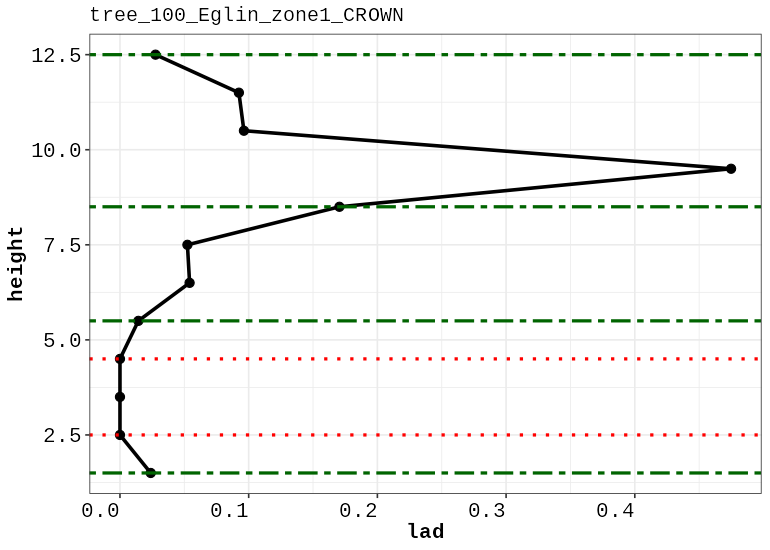

01_gaps_fbh_10_Eglin_zone1_CROWN.png


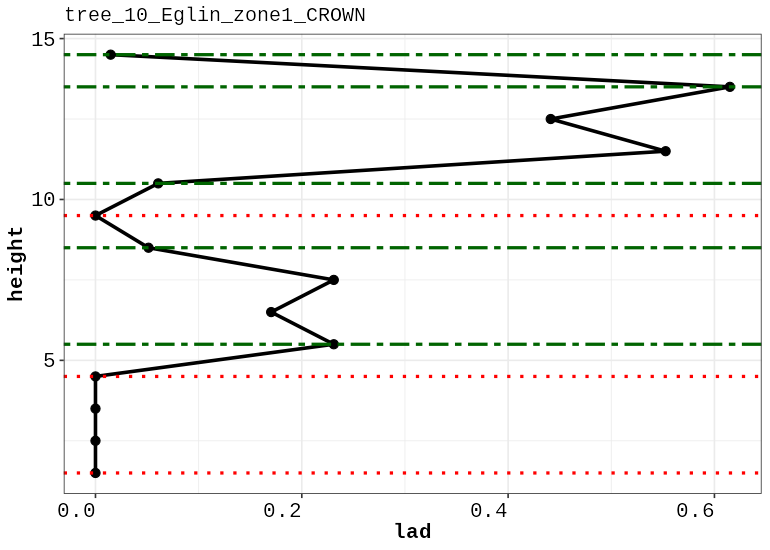

01_gaps_fbh_1_Eglin_zone1_CROWN.png


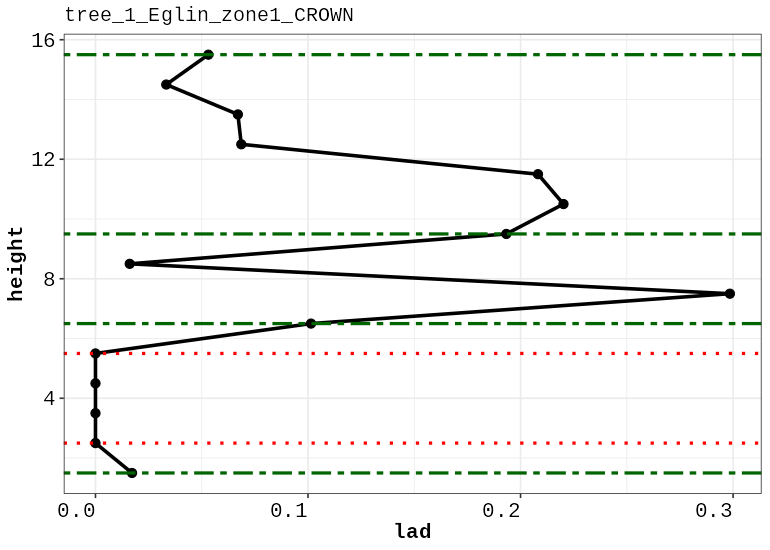

In [ ]:
plot_gaps_r = r"""
suppressPackageStartupMessages({library(LadderFuelsR); library(ggplot2)})
profile_list2 <- readRDS("/content/rds/profile_list2.rds")
gaps_fbhs_metrics <- readRDS("/content/rds/gaps_fbhs_metrics.rds")
plots_gaps_fbhs <- get_plots_gap_fbh(profile_list2, gaps_fbhs_metrics, min_height = 1.5)
dir.create("/content/outputs", showWarnings = FALSE, recursive = TRUE)
for (nm in names(plots_gaps_fbhs)) {
  ggsave(file.path("/content/outputs", paste0("01_gaps_fbh_", nm, ".png")),
         plot = plots_gaps_fbhs[[nm]], width = 7, height = 5, dpi = 110)
}
cat("saved plots for trees:", paste(names(plots_gaps_fbhs), collapse = ", "), "\n")
"""
result = subprocess.run([RSCRIPT, "-e", plot_gaps_r], check=True, capture_output=True, text=True, timeout=900)
print(result.stdout)

from IPython.display import Image, display
for png in sorted(__import__("pathlib").Path("/content/outputs").glob("01_gaps_fbh_*.png")):
    print(png.name)
    display(Image(filename=str(png), width=560))


## 7. Steps 14–16 — Effective (recalculated) FBHs, depths, and distances (paper §2.5)

After the raw detection, the authors recalculate metrics when layers are separated by more than `number_steps = 1` height bins: `get_real_fbh()` propagates the first FBH of consecutive FBH sets, `get_real_depths()` accumulates depths of layers separated by exactly `number_steps`, and `get_effective_gap()` keeps only distances where consecutive FBHs actually differ. (README tables 14–16.)

**日本語:** `number_steps = 1` を超えて離れた層の扱いを補正します：`get_real_fbh()`（連続 FBH の先頭を伝播）、`get_real_depths()`（離れた層の深度を合算）、`get_effective_gap()`（実効距離のみ残す）（論文 §2.5、README 表 14–16）。

In [ ]:
effective_r = r"""
suppressPackageStartupMessages({library(LadderFuelsR); library(dplyr); library(magrittr); library(stringr)})
depth_metrics <- readRDS("/content/rds/depth_metrics.rds")
trees_name2 <- factor(unique(as.character(depth_metrics$treeID)))

fbh_corr_list <- list()
for (i in levels(trees_name2)) {
  tree3 <- depth_metrics |> dplyr::filter(treeID == i)
  fbh_corr_list[[i]] <- get_real_fbh(tree3, step = 1, number_steps = 1, min_height = 1.5)
}
fbh_metrics_corr <- dplyr::bind_rows(fbh_corr_list)
fbh_metrics_corr$treeID <- factor(fbh_metrics_corr$treeID)
original_column_names <- colnames(fbh_metrics_corr)
prefixes <- c("treeID", "Hdist", "Hcbh", "Hdepth", "dist", "depth", "max_height")
new_order <- unlist(lapply(prefixes, function(p) grep(paste0("^", p), original_column_names, value = TRUE)))
fbh_metrics_corr <- fbh_metrics_corr[, new_order]
rownames(fbh_metrics_corr) <- NULL
saveRDS(fbh_metrics_corr, "/content/rds/fbh_metrics_corr.rds")
cat("== Corrected FBHs (README table 14) ==\n")
print(head(fbh_metrics_corr))

depth_corr_list <- lapply(levels(trees_name2), function(i) {
  tree2 <- fbh_metrics_corr |> dplyr::filter(treeID == i)
  get_real_depths(tree2, step = 1, min_height = 1.5)
})
depth_metrics_corr <- dplyr::bind_rows(depth_corr_list)
rownames(depth_metrics_corr) <- NULL
saveRDS(depth_metrics_corr, "/content/rds/depth_metrics_corr.rds")
cat("== Corrected depths (README table 15) ==\n")
print(head(depth_metrics_corr))

dist_corr_list <- lapply(levels(trees_name2), function(i) {
  tree2 <- depth_metrics_corr |> dplyr::filter(treeID == i)
  get_effective_gap(tree2, number_steps = 1, min_height = 1.5)
})
distances_metrics_corr <- dplyr::bind_rows(dist_corr_list)
original_column_names <- colnames(distances_metrics_corr)
prefixes <- c("treeID", "Hcbh", "dptf", "Hdptf", "effdist", "dist", "Hdist",
              "max_Hcbh", "max_dptf", "max_Hdptf", "last_Hcbh", "last_dptf",
              "last_Hdptf", "max_height")
new_order <- unlist(lapply(prefixes, function(p) grep(paste0("^", p), original_column_names, value = TRUE)))
distances_metrics_corr1 <- distances_metrics_corr[, new_order]
distances_metrics_corr2 <- as.data.frame(lapply(distances_metrics_corr1, function(x) unlist(x)))
rownames(distances_metrics_corr2) <- NULL
saveRDS(distances_metrics_corr2, "/content/rds/distances_metrics_corr2.rds")
cat("== Effective distances (README table 16) ==\n")
print(head(distances_metrics_corr2))
"""
result = subprocess.run([RSCRIPT, "-e", effective_r], check=True, capture_output=True, text=True, timeout=900)
print(result.stdout)


== Corrected FBHs (README table 14) ==
  treeID1                treeID Hdist1 Hdist2 Hcbh1 Hcbh2 Hdepth1 Hdepth2 dist1
1       1   1_Eglin_zone1_CROWN    1.5    5.5   1.5   6.5     1.5    15.5   1.5
2      10  10_Eglin_zone1_CROWN    4.5    9.5   5.5   5.5     8.5    14.5   4.0
3     100 100_Eglin_zone1_CROWN    1.5    4.5   1.5   5.5     1.5    12.5   1.5
  dist2 depth1 depth2 max_height
1     4      1      9       15.5
2     1      3      4       14.5
3     3      1      7       12.5
== Corrected depths (README table 15) ==
                 treeID treeID1 Hdptf1 Hdptf2 dist1 dist2 dptf1 dptf2 Hcbh1
1   1_Eglin_zone1_CROWN       1    1.5   15.5     0     4     1     9   1.5
2  10_Eglin_zone1_CROWN      10   14.5     NA     4    NA     9    NA   5.5
3 100_Eglin_zone1_CROWN     100    1.5   12.5     0     3     1     7   1.5
  Hcbh2 Hdist1 Hdist2 max_height
1   6.5    1.5    5.5       15.5
2    NA    4.5     NA       14.5
3   5.5    1.5    4.5       12.5
== Effective distances (README t

## 8. Steps 17–18 — LAD% per fuel layer, threshold at 10% (paper §2.7)

`get_layers_lad()` computes the percentage of the tree's total LAD contained in each fuel layer (using the original profile) and **removes layers below `threshold = 10` %**, recalculating distances. `df2` is the effective-layer table used by all CBH criteria. Plots show the surviving effective layers.

**日本語:** `get_layers_lad()` が各燃料層の LAD 占有率を計算し、**`threshold = 10` % 未満の層を除去**して距離を再計算します（論文 §2.7）。`df2` が CBH 計算に使われる有効層表です。

== Effective fuel layers with LAD% > 10 (README table 17) ==
  treeID1                treeID Hdist1 Hcbh1 Hcbh1_Hdptf1 effdist1 dptf1 Hdptf1
1       1   1_Eglin_zone1_CROWN    5.5   6.5     98.65299        5     9   15.5
2      10  10_Eglin_zone1_CROWN    4.5   5.5    100.00000        4     9   14.5
3     100 100_Eglin_zone1_CROWN    4.5   5.5     97.62496        4     7   12.5
  max1 max_height nlayers
1 15.5       15.5       1
2 14.5       14.5       1
3 12.5       12.5       1
saved plots for trees: 1_Eglin_zone1_CROWN, 10_Eglin_zone1_CROWN, 100_Eglin_zone1_CROWN 

02_effective_layers_100_Eglin_zone1_CROWN.png


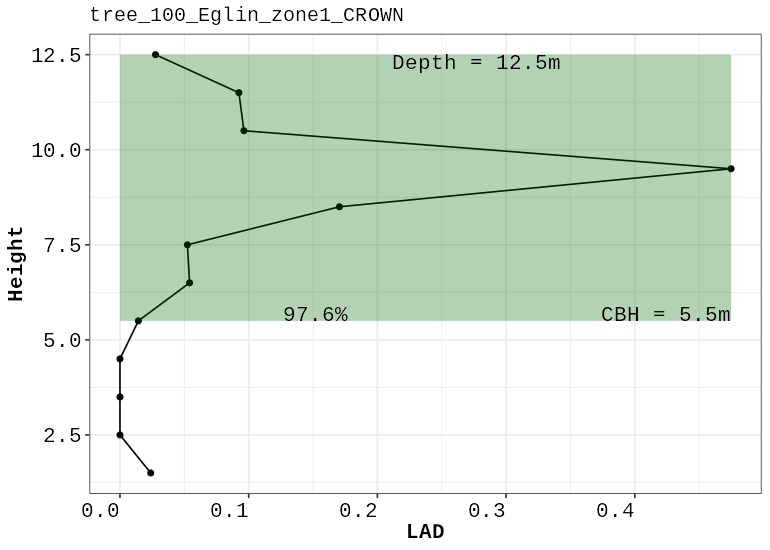

02_effective_layers_10_Eglin_zone1_CROWN.png


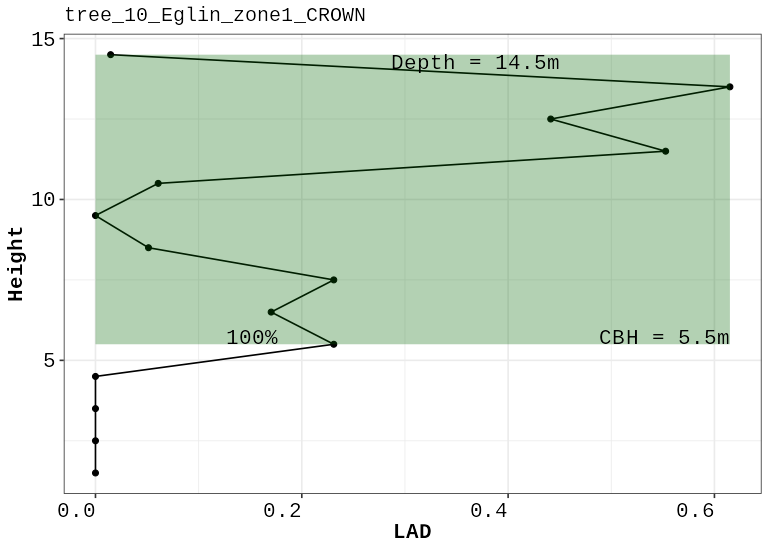

In [ ]:
lad_layer_r = r"""
suppressPackageStartupMessages({library(LadderFuelsR); library(dplyr); library(magrittr); library(ggplot2)})
profile_list2 <- readRDS("/content/rds/profile_list2.rds")
distances_metrics_corr2 <- readRDS("/content/rds/distances_metrics_corr2.rds")
trees_name2 <- factor(unique(as.character(distances_metrics_corr2$treeID)))

LAD_metrics1 <- list(); LAD_metrics2 <- list()
for (i in levels(trees_name2)) {
  tree1 <- profile_list2 |> dplyr::filter(treeID == i)
  tree2 <- distances_metrics_corr2 |> dplyr::filter(treeID == i)
  LAD_metrics <- get_layers_lad(tree1, tree2, threshold = 10, step = 1, min_height = 1.5)
  LAD_metrics1[[i]] <- LAD_metrics$df1
  LAD_metrics2[[i]] <- LAD_metrics$df2
}
fuels_LAD_metrics <- list(dplyr::bind_rows(LAD_metrics1), dplyr::bind_rows(LAD_metrics2))
prefixes <- c("treeID", "Hdist", "Hcbh", "effdist", "dptf", "Hdptf", "max", "last", "nlayers")
for (k in seq_along(fuels_LAD_metrics)) {
  df_k <- fuels_LAD_metrics[[k]]
  original_column_names <- colnames(df_k)
  new_order <- unlist(lapply(prefixes, function(p) grep(paste0("^", p), original_column_names, value = TRUE)))
  fuels_LAD_metrics[[k]] <- df_k[, new_order]
  rownames(fuels_LAD_metrics[[k]]) <- NULL
}
LAD_gt10p <- fuels_LAD_metrics[[2]]
saveRDS(fuels_LAD_metrics, "/content/rds/fuels_LAD_metrics.rds")
cat("== Effective fuel layers with LAD% > 10 (README table 17) ==\n")
print(head(LAD_gt10p))

plots_trees_LAD <- get_plots_effective(profile_list2, LAD_gt10p, min_height = 1.5)
for (nm in names(plots_trees_LAD)) {
  ggsave(file.path("/content/outputs", paste0("02_effective_layers_", nm, ".png")),
         plot = plots_trees_LAD[[nm]], width = 7, height = 5, dpi = 110)
}
cat("saved plots for trees:", paste(names(plots_trees_LAD), collapse = ", "), "\n")
"""
result = subprocess.run([RSCRIPT, "-e", lad_layer_r], check=True, capture_output=True, text=True, timeout=900)
print(result.stdout)

from IPython.display import Image, display
import pathlib
for png in sorted(pathlib.Path("/content/outputs").glob("02_effective_layers_*.png"))[:2]:
    print(png.name)
    display(Image(filename=str(png), width=560))


## 9. Steps 19–20 — CBH from three criteria (paper §2.8)

`get_cbh_metrics()` assigns each tree's crown base height by three criteria: (a) the fuel layer containing the **maximum LAD%** (when the first layer's depth < `hdepth1_height = 2.5` m, the second layer is output), (b) the layer at the **highest distance**, and (c) the layer at the **last effective distance**. The plots overlay each criterion's CBH on the profile (README fig20).

**日本語:** `get_cbh_metrics()` が 3 つの基準で CBH を推定します：(a) **最大 LAD%** の燃料層（第 1 層の深度 < 2.5 m の場合は第 2 層）、(b) **最大距離**位置の層、(c) **最終実効距離**位置の層（論文 §2.8）。図は各基準の CBH をプロファイル上に重ねます。

== CBH by three criteria (README table 19) ==
  treeID1                treeID Hcbh1 Hcbh1_Hdptf1 dptf1 effdist1 Hdist1 Hdptf1
1       1   1_Eglin_zone1_CROWN   6.5     98.65299     9        5    5.5   15.5
2      10  10_Eglin_zone1_CROWN   5.5    100.00000     9        4    4.5   14.5
3     100 100_Eglin_zone1_CROWN   5.5     97.62496     7        4    4.5   12.5
  maxlad_Hcbh maxlad_Hdist maxlad_Hdptf maxlad_dptf maxlad_effdist maxlad_lad
1         6.5          5.5         15.5           9              5   98.65299
2         5.5          4.5         14.5           9              4  100.00000
3         5.5          4.5         12.5           7              4   97.62496
  max_height max_Hcbh max_Hdist max_Hdptf max_dptf max_effdist   max_lad
1       15.5      6.5       5.5      15.5        9           5  98.65299
2       14.5      5.5       4.5      14.5        9           4 100.00000
3       12.5      5.5       4.5      12.5        7           4  97.62496
  last_Hcbh last_Hdist last_Hd

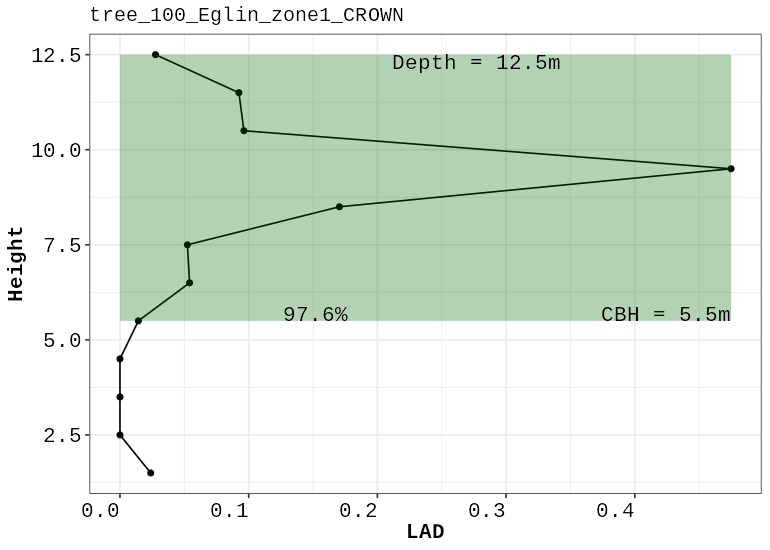

03_cbh_maxlad_10_Eglin_zone1_CROWN.png


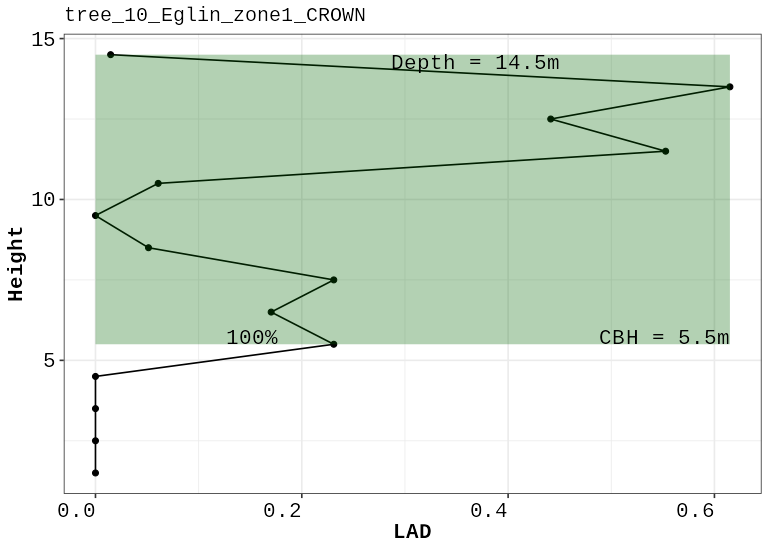

In [ ]:
cbh_criteria_r = r"""
suppressPackageStartupMessages({library(LadderFuelsR); library(dplyr); library(ggplot2)})
profile_list2 <- readRDS("/content/rds/profile_list2.rds")
fuels_LAD_metrics <- readRDS("/content/rds/fuels_LAD_metrics.rds")
LAD_gt10p <- fuels_LAD_metrics[[2]]
trees_name2 <- factor(unique(as.character(LAD_gt10p$treeID)))

cbh_metrics_list <- list()
for (j in levels(trees_name2)) {
  tree1 <- LAD_gt10p |> dplyr::filter(treeID == j)
  cbh_metrics_list[[j]] <- get_cbh_metrics(tree1, min_height = 1.5)
}
cbh_metrics_all <- dplyr::bind_rows(cbh_metrics_list)
original_column_names <- colnames(cbh_metrics_all)
desired_order <- c("treeID", "Hcbh", "dptf", "effdist", "dist", "Hdist", "Hdptf",
                   "maxlad_", "max_", "last_", "nlayers")
new_order <- unlist(lapply(desired_order, function(p) grep(paste0("^", p), original_column_names, value = TRUE)))
cbh_metrics_all <- cbh_metrics_all[, new_order]
cbh_metrics_all$treeID <- factor(cbh_metrics_all$treeID)
saveRDS(cbh_metrics_all, "/content/rds/cbh_metrics_all.rds")
cat("== CBH by three criteria (README table 19) ==\n")
print(head(cbh_metrics_all))

plots_cbh_maxlad <- get_plots_cbh_LAD(profile_list2, cbh_metrics_all, min_height = 1.5)
plots_cbh_maxdist <- get_plots_cbh_maxdist(profile_list2, cbh_metrics_all, min_height = 1.5)
plots_cbh_lastdist <- get_plots_cbh_lastdist(profile_list2, cbh_metrics_all, min_height = 1.5)
for (nm in names(plots_cbh_maxlad)) {
  ggsave(file.path("/content/outputs", paste0("03_cbh_maxlad_", nm, ".png")),
         plot = plots_cbh_maxlad[[nm]], width = 7, height = 5, dpi = 110)
  ggsave(file.path("/content/outputs", paste0("04_cbh_maxdist_", nm, ".png")),
         plot = plots_cbh_maxdist[[nm]], width = 7, height = 5, dpi = 110)
  ggsave(file.path("/content/outputs", paste0("05_cbh_lastdist_", nm, ".png")),
         plot = plots_cbh_lastdist[[nm]], width = 7, height = 5, dpi = 110)
}
cat("saved CBH-criteria plots for trees:", paste(names(plots_cbh_maxlad), collapse = ", "), "\n")
"""
result = subprocess.run([RSCRIPT, "-e", cbh_criteria_r], check=True, capture_output=True, text=True, timeout=900)
print(result.stdout)

from IPython.display import Image, display
import pathlib
for png in sorted(pathlib.Path("/content/outputs").glob("03_cbh_maxlad_*.png"))[:2]:
    print(png.name)
    display(Image(filename=str(png), width=560))


## 10. Steps 21–22 — Breakpoint CBH on cumulative LAD (paper §2.9, `get_cum_break()`)

When a profile yields a single fuel layer at the minimum base height, the authors fit a **segmented linear regression** (`segmented` package) to cumulative LAD vs. height; the breakpoint (BP) is the CBH candidate. With `threshold = 75`: if the LAD% below or above the BP is < 75%, the max-LAD criterion CBH is used instead. The plot shows cumulative LAD with the fitted breakpoint (README fig22).

**日本語:** 単一燃料層で CBH が最小基底高になる場合、累積 LAD vs 高さへの**セグメント回帰**（`segmented` パッケージ）で折れ点（BP）を CBH 候補とします。BP 上下の LAD% が 75% 未満なら最大 LAD 基準の CBH を採用（論文 §2.9）。

> **Reproducibility note (added after validation, markdown-only edit):** the authors' `get_cum_break()` jitters the profile heights (`jitter(height, amount = 1)`, R/cummLAD_breaks_metrics.R @ 6eb099c) without a fixed seed, so the breakpoint CBH varies by up to ≈1 m between runs; observed bp_Hcbh for `1_Eglin_zone1_CROWN` was 5.2 m and 4.6 m in two fresh runs, while the three distance/LAD-criteria CBHs were identical (6.5 m). **日本語:** 著者コードの `jitter()` に乱数シードがないため、折れ点 CBH は実行ごとに約 ±1 m 変動します。


== Breakpoint CBH and LAD% below/above (README table 21) ==
                 treeID treeID1 Hcbh_brpt below_hcbhbp above_hcbhbp bp_Hcbh
1   1_Eglin_zone1_CROWN       1  4.607774     1.347012     98.65299     4.6
2  10_Eglin_zone1_CROWN      10  9.382803    28.870028     73.30040     5.5
3 100_Eglin_zone1_CROWN     100  6.523533     9.172215     96.20392     6.5
  bp_Hdptf bp_Hdist bp_effdist bp_dptf    bp_lad max_height cumlad
1     15.5      3.6          4      11  98.65299       15.5 0.0172
2     14.5      4.5          4       9 100.00000       14.5 0.6837
3     12.5      5.5          6       6  96.20392       12.5 0.0923
saved breakpoint plots

06_cbh_bp_100_Eglin_zone1_CROWN_1.png


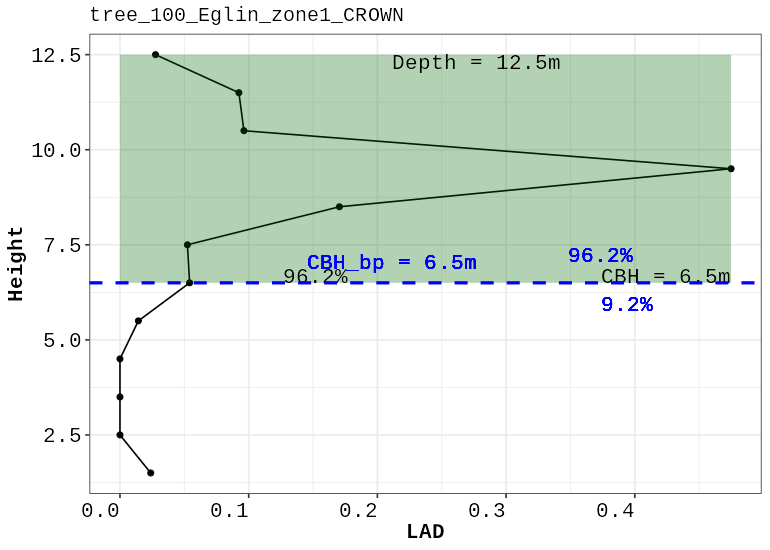

06_cbh_bp_10_Eglin_zone1_CROWN_1.png


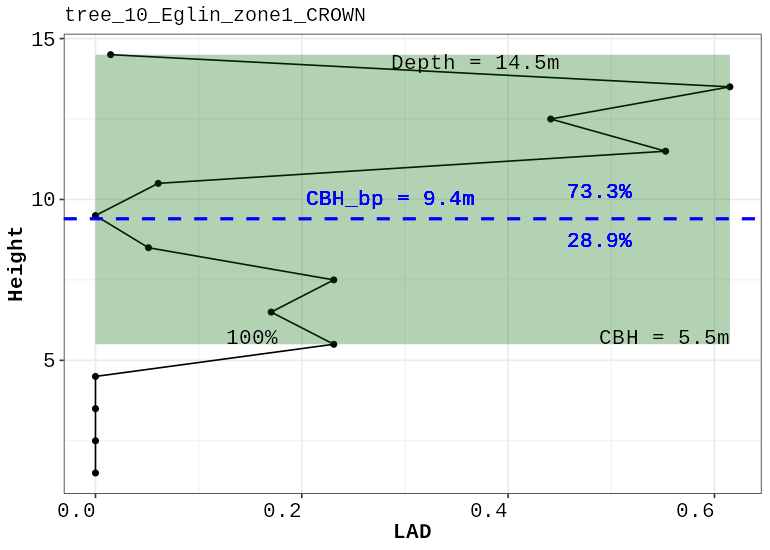

In [ ]:
cum_break_r = r"""
suppressPackageStartupMessages({library(LadderFuelsR); library(dplyr); library(ggplot2)})
profile_list2 <- readRDS("/content/rds/profile_list2.rds")
cbh_metrics_all <- readRDS("/content/rds/cbh_metrics_all.rds")
trees_name2 <- factor(unique(as.character(profile_list2$treeID)))

cum_LAD_metrics_list <- list()
for (i in levels(trees_name2)) {
  tree1 <- profile_list2 |> dplyr::filter(treeID == i)
  tree2 <- cbh_metrics_all |> dplyr::filter(treeID == i)
  cum_LAD_metrics_list[[i]] <- get_cum_break(tree1, tree2, threshold = 75,
                                             min_height = 1.5, verbose = TRUE)
}
cum_LAD_metrics <- dplyr::bind_rows(cum_LAD_metrics_list)
original_column_names <- colnames(cum_LAD_metrics)
prefixes <- c("treeID", "Hcbh", "below", "above", "bp", "max", "cumlad")
new_order <- unlist(lapply(prefixes, function(p) grep(paste0("^", p), original_column_names, value = TRUE)))
cum_LAD_metrics <- cum_LAD_metrics[, new_order]
cum_LAD_metrics$treeID <- factor(cum_LAD_metrics$treeID)
rownames(cum_LAD_metrics) <- NULL
saveRDS(cum_LAD_metrics, "/content/rds/cum_LAD_metrics.rds")
cat("== Breakpoint CBH and LAD% below/above (README table 21) ==\n")
print(head(cum_LAD_metrics))

for (j in levels(trees_name2)) {
  tree1 <- profile_list2 |> dplyr::filter(treeID == j)
  tree2 <- cum_LAD_metrics |> dplyr::filter(treeID == j)
  plots_cbh_bp <- get_plots_cbh_bp(tree1, tree2, min_height = 1.5)
  for (k in seq_along(plots_cbh_bp)) {
    ggsave(file.path("/content/outputs", sprintf("06_cbh_bp_%s_%d.png", j, k)),
           plot = plots_cbh_bp[[k]], width = 7, height = 5, dpi = 110)
  }
}
cat("saved breakpoint plots\n")
"""
result = subprocess.run([RSCRIPT, "-e", cum_break_r], check=True, capture_output=True, text=True, timeout=900)
print(result.stdout)

from IPython.display import Image, display
import pathlib
for png in sorted(pathlib.Path("/content/outputs").glob("06_cbh_bp_*.png"))[:2]:
    print(png.name)
    display(Image(filename=str(png), width=560))


## 11. Results — per-tree CBH summary and CSV export

We collect the final quantitative outputs: the three distance/LAD-criteria CBH values (`get_cbh_metrics`) and the breakpoint CBH with LAD% below/above (`get_cum_break`). Heights are metres, as in the paper. A CSV is written for further use.

**日本語:** 各樹木の 3 基準 CBH と折れ点 CBH（BP 上下の LAD%）を集計し、CSV に書き出します。単位はメートルです。

In [ ]:
export_r = r"""
cbh_metrics_all <- readRDS("/content/rds/cbh_metrics_all.rds")
cum_LAD_metrics <- readRDS("/content/rds/cum_LAD_metrics.rds")
write.csv(cbh_metrics_all, "/content/outputs/cbh_metrics_by_criteria.csv", row.names = FALSE)
write.csv(cum_LAD_metrics, "/content/outputs/cbh_metrics_breakpoint.csv", row.names = FALSE)
cat("columns:", paste(names(cbh_metrics_all), collapse = ", "), "\n")
cat("rows:", nrow(cbh_metrics_all), "\n")
"""
result = subprocess.run([RSCRIPT, "-e", export_r], check=True, capture_output=True, text=True, timeout=300)
print(result.stdout)

import pandas as pd
pd.set_option("display.width", 160)
cbh = pd.read_csv("/content/outputs/cbh_metrics_by_criteria.csv")
bp = pd.read_csv("/content/outputs/cbh_metrics_breakpoint.csv")
keep_cbh = [c for c in ["treeID", "maxlad_Hcbh", "max_Hcbh", "last_Hcbh", "nlayers"] if c in cbh.columns]
keep_bp = [c for c in ["treeID", "bp_Hcbh", "bp_below_LAD", "bp_above_LAD"] if c in bp.columns]
print("CBH [m] by criteria (subset):")
print(cbh[keep_cbh].to_string(index=False) if keep_cbh else cbh.head().to_string(index=False))
print("\nBreakpoint CBH (subset):")
print(bp[keep_bp].to_string(index=False) if keep_bp else bp.head().to_string(index=False))
print("\nCSV written to /content/outputs/cbh_metrics_by_criteria.csv and cbh_metrics_breakpoint.csv")


columns: treeID1, treeID, Hcbh1, Hcbh1_Hdptf1, dptf1, effdist1, Hdist1, Hdptf1, maxlad_Hcbh, maxlad_Hdist, maxlad_Hdptf, maxlad_dptf, maxlad_effdist, maxlad_lad, max_height, max_Hcbh, max_Hdist, max_Hdptf, max_dptf, max_effdist, max_lad, last_Hcbh, last_Hdist, last_Hdptf, last_dptf, last_effdist, last_lad, nlayers 
rows: 3 

CBH [m] by criteria (subset):
               treeID  maxlad_Hcbh  max_Hcbh  last_Hcbh  nlayers
  1_Eglin_zone1_CROWN          6.5       6.5        6.5        1
 10_Eglin_zone1_CROWN          5.5       5.5        5.5        1
100_Eglin_zone1_CROWN          5.5       5.5        5.5        1

Breakpoint CBH (subset):
               treeID  bp_Hcbh
  1_Eglin_zone1_CROWN      4.6
 10_Eglin_zone1_CROWN      5.5
100_Eglin_zone1_CROWN      6.5

CSV written to /content/outputs/cbh_metrics_by_criteria.csv and cbh_metrics_breakpoint.csv


## 12. Interpretation, validation record, and limitations

**What this demonstrates:** the full LadderFuelsR gap/FBH → distance → depth → effective-layer → LAD% → CBH pipeline (paper §2.2–2.9) executed on the authors' own bundled sample, using the authors' unmodified R code (LadderFuelsR 0.0.7). Outputs are labelled with their sample tree IDs; all heights are metres above ground.

**What it does not verify:** the paper's multi-sensor accuracy assessment against field CBH (Florida *P. palustris* / Eglin data, USDA RDS-2023-0008) is out of scope, as are README steps 1–7 (CHM, crown segmentation, leafR voxel LAD profiling — `leafR` was removed from CRAN 2026-03-21). A one-sample run does not validate published dataset-level results. The README's §16/§21 snippets hardcode `treeID == "1_CROWN"` inside per-tree loops; we used the intended generic loop.

**Reproducibility record:** pinned package (CRAN 0.0.7) and pinned data commit `6eb099c164b227dac68f5d06d781bd5ef13794fd`; the sample download is checksum-verified above. Package versions are printed in section 2.

**References:** paper DOI 10.1111/2041-210X.14427 (CC BY 4.0); CRAN: <https://CRAN.R-project.org/package=LadderFuelsR>; author repository and sample data: <https://github.com/olgaviedma/LadderFuelsR> (GPL-3).

**日本語:** 本ノートブックは論文 §2.2–2.9 の LadderFuelsR パイプラインを著者同梱サンプル・著者コード（無改修）で実行する**部分再現**です。論文のセンサーマトリクス精度検証や README ステップ 1–7（CHM・樹冠分割・leafR による LAD 計算）は対象外です。単一サンプルの実行はデータセット全体の結果検証ではありません。